# Bài 06 - Phần 1: Khái niệm, công thức và code để hiểu RNN

Notebook này đi từ công thức tới code theo một nguyên tắc: **mỗi công thức được viết
lại bằng NumPy rồi đối chiếu với lớp có sẵn của PyTorch**. Khi hai bên cho cùng một
con số đến sai số làm tròn thì có thể chắc là đã hiểu đúng lớp đó tính gì. Phần Keras
tương ứng nằm ở đầu notebook 04.

Nội dung: (1) dữ liệu chuỗi và quy ước kích thước tensor, (2) ô RNN và phép trải
theo thời gian, (3) các hàm kích hoạt, (4) lan truyền ngược theo thời gian (BPTT) tự
viết, (5) gradient tiêu biến và bùng nổ, (6) LSTM, (7) GRU, (8) thí nghiệm trí nhớ, (9)
các kiểu kiến trúc và API.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

import lab06_data as D

torch.set_num_threads(8)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 130, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})


def save(fig, name):
    fig.savefig(D.RESULTS / name, bbox_inches="tight")


def sigm(x):
    return 1.0 / (1.0 + np.exp(-x))


print("torch", torch.__version__, "| numpy", np.__version__)

torch 2.10.0+cpu | numpy 2.4.2


## 1. Dữ liệu chuỗi và quy ước kích thước

Một mạng truyền thẳng (MLP) nhận đầu vào có kích thước cố định và coi mọi thành phần
là độc lập về vị trí. Dữ liệu chuỗi thì khác ở hai điểm: độ dài có thể thay đổi, và
thứ tự mang thông tin (giá hôm qua đứng trước giá hôm nay). RNN giải quyết cả hai
bằng cách dùng **cùng một bộ trọng số** ở mọi bước và mang theo một **trạng thái ẩn**
h_t tóm tắt những gì đã đọc.

Mọi tensor trong bài đều theo quy ước `(batch, time, feature)`:

| Bộ dữ liệu | batch | time | feature | Ý nghĩa một bước |
|---|---|---|---|---|
| Churn | số khách | 11 | 1 | một đặc trưng của khách hàng |
| AMZN | số cửa sổ | 60 | 3 | một phiên giao dịch: lợi suất, biên độ, khối lượng |

PyTorch mặc định là `(time, batch, feature)`, nên mọi lớp trong bài đều truyền
`batch_first=True`. Keras mặc định đã là `(batch, time, feature)`.

## 2. Ô RNN và phép trải theo thời gian

Ô RNN thuần (Elman) cập nhật trạng thái ẩn theo công thức

$$h_t = \tanh(W_{ih} x_t + b_{ih} + W_{hh} h_{t-1} + b_{hh}), \qquad h_0 = 0$$

với x_t có F chiều, h_t có H chiều, W_ih kích thước H x F, W_hh kích thước H x H. Đầu
ra ở bước t (nếu cần) là y_t = W_hy h_t + b_y. "Trải theo thời gian" (unrolling) nghĩa
là viết vòng lặp trên thành một đồ thị tính toán T tầng, mỗi tầng dùng chung W_ih,
W_hh. Hàm dưới đây là đúng vòng lặp đó.

In [2]:
def rnn_forward_numpy(X, W_ih, W_hh, b_ih, b_hh, h0=None):
    """X: (B, T, F). Tra ve moi trang thai an (B, T, H) va trang thai cuoi h_T (B, H).

    h_t = tanh(x_t W_ih^T + b_ih + h_{t-1} W_hh^T + b_hh): cung mot bo trong so o moi buoc.
    """
    B, T, _ = X.shape
    H = W_hh.shape[0]
    h = np.zeros((B, H)) if h0 is None else h0
    hs = []
    for t in range(T):
        h = np.tanh(X[:, t] @ W_ih.T + b_ih + h @ W_hh.T + b_hh)
        hs.append(h)
    return np.stack(hs, axis=1), h


torch.manual_seed(0)
rnn = nn.RNN(input_size=3, hidden_size=4, batch_first=True)
X = torch.randn(2, 5, 3)                       # 2 chuoi, 5 buoc, 3 dac trung
out_t, hn_t = rnn(X)
W = {k: v.detach().numpy().astype(np.float64) for k, v in rnn.named_parameters()}
out_np, hn_np = rnn_forward_numpy(X.numpy().astype(np.float64), W["weight_ih_l0"],
                                  W["weight_hh_l0"], W["bias_ih_l0"], W["bias_hh_l0"])
for k, v in W.items():
    print("%-14s %s" % (k, v.shape))
print("out PyTorch", tuple(out_t.shape), "| h_n PyTorch", tuple(hn_t.shape))
print("chenh lech lon nhat giua NumPy va nn.RNN: out %.2e, h_n %.2e"
      % (np.abs(out_np - out_t.detach().numpy()).max(),
         np.abs(hn_np - hn_t[0].detach().numpy()).max()))
print("out[:, -1] trung h_n:", torch.allclose(out_t[:, -1], hn_t[0]))

weight_ih_l0   (4, 3)
weight_hh_l0   (4, 4)
bias_ih_l0     (4,)
bias_hh_l0     (4,)
out PyTorch (2, 5, 4) | h_n PyTorch (1, 2, 4)
chenh lech lon nhat giua NumPy va nn.RNN: out 7.14e-08, h_n 2.59e-08
out[:, -1] trung h_n: True


Ba điều rút ra từ kết quả trên:

- `nn.RNN` tính đúng công thức, chênh lệch cỡ 1e-7 là sai số làm tròn float32.
- `out` chứa trạng thái ẩn ở **mọi** bước `(B, T, H)`, còn `h_n` chỉ chứa bước cuối
  `(num_layers, B, H)`. Với mạng một tầng, một chiều thì `out[:, -1]` chính là `h_n[0]`.
  Bài toán nhiều-một dùng một trong hai, bài toán nhiều-nhiều dùng `out`.
- PyTorch giữ hai vectơ bias `b_ih` và `b_hh` dù về toán chỉ cần tổng của chúng. Đó
  là lý do số tham số là H(F + H + 2) chứ không phải H(F + H + 1).

Số tham số không phụ thuộc độ dài chuỗi, vì mọi bước dùng chung trọng số:

In [3]:
for T in (5, 50, 500):
    y, _ = rnn(torch.randn(1, T, 3))
    print("T = %3d -> out %s, so tham so van la %d"
          % (T, tuple(y.shape), sum(p.numel() for p in rnn.parameters())))

T =   5 -> out (1, 5, 4), so tham so van la 36
T =  50 -> out (1, 50, 4), so tham so van la 36
T = 500 -> out (1, 500, 4), so tham so van la 36


## 3. Các hàm kích hoạt trong RNN

| Hàm | Công thức | Miền giá trị | Đạo hàm lớn nhất | Vai trò |
|---|---|---|---|---|
| tanh | (e^x - e^-x)/(e^x + e^-x) | (-1, 1) | 1 tại 0 | biến đổi trạng thái ẩn, ứng viên nhớ |
| sigmoid σ | 1/(1 + e^-x) | (0, 1) | 0,25 tại 0 | các cổng của LSTM, GRU: "mở bao nhiêu phần" |
| ReLU | max(0, x) | [0, ∞) | 1 | ít dùng trong ô hồi quy vì không chặn trên |
| softmax | e^{z_k}/Σ e^{z_j} | (0, 1), tổng 1 | | đầu ra phân nhiều lớp |

Trạng thái ẩn dùng tanh vì nó bị chặn trong (-1, 1): lặp lại phép nhân với W_hh qua
hàng trăm bước mà không có chặn thì giá trị sẽ phình ra. Cổng dùng sigmoid vì cần
một hệ số trong (0, 1) để nhân từng phần tử. Đạo hàm của cả hai đều nhỏ hơn hoặc bằng 1,
và đây là một nửa nguyên nhân của gradient tiêu biến ở mục 5.

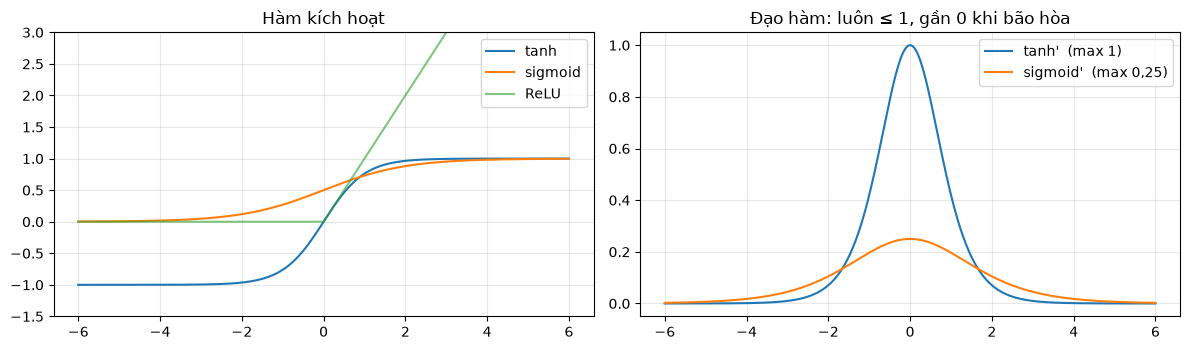

softmax [[0.659   0.24243 0.09857]] tong = 1.0000001192092896
tanh'(0) = 1.000, tanh'(3) = 0.0099 | sigmoid'(0) = 0.250, sigmoid'(4) = 0.0177


In [4]:
x = np.linspace(-6, 6, 400)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
a1.plot(x, np.tanh(x), label="tanh")
a1.plot(x, sigm(x), label="sigmoid")
a1.plot(x, np.maximum(0, x), label="ReLU", alpha=0.6)
a1.set_ylim(-1.5, 3)
a1.set_title("Hàm kích hoạt")
a1.legend()
a2.plot(x, 1 - np.tanh(x) ** 2, label="tanh'  (max 1)")
a2.plot(x, sigm(x) * (1 - sigm(x)), label="sigmoid'  (max 0,25)")
a2.set_title("Đạo hàm: luôn ≤ 1, gần 0 khi bão hòa")
a2.legend()
fig.tight_layout()
save(fig, "fig_activations_rnn.png")
plt.show()

z = torch.tensor([[2.0, 1.0, 0.1]])
print("softmax", torch.softmax(z, dim=-1).numpy(), "tong =", torch.softmax(z, dim=-1).sum().item())
print("tanh'(0) = %.3f, tanh'(3) = %.4f | sigmoid'(0) = %.3f, sigmoid'(4) = %.4f"
      % (1 - np.tanh(0) ** 2, 1 - np.tanh(3) ** 2, 0.25, sigm(4) * (1 - sigm(4))))

## 4. Lan truyền ngược theo thời gian (BPTT)

Với bài toán nhiều-một, dự báo là ŷ = W_hy h_T + b_y và hàm mất mát L = ½·mean(ŷ - y)².
Gradient chảy ngược từ h_T về h_{T-1}, ..., h_1. Đặt a_t là đầu vào của tanh ở bước t,
các công thức cho một bước là:

$$\frac{\partial L}{\partial a_t} = \frac{\partial L}{\partial h_t} \odot (1 - h_t^2), \qquad
\frac{\partial L}{\partial h_{t-1}} = \frac{\partial L}{\partial a_t} W_{hh}$$

$$\frac{\partial L}{\partial W_{hh}} = \sum_t \Big(\frac{\partial L}{\partial a_t}\Big)^\top h_{t-1}, \qquad
\frac{\partial L}{\partial W_{ih}} = \sum_t \Big(\frac{\partial L}{\partial a_t}\Big)^\top x_t$$

Gradient của trọng số là **tổng qua mọi bước** vì trọng số được dùng chung. Hàm dưới
đây cài đúng các công thức đó, sau đó so với `autograd` của PyTorch.

In [5]:
def rnn_bptt_numpy(X, y, W_ih, W_hh, b, W_hy, b_y):
    """Lan truyen xuoi va nguoc cho RNN nhieu-mot, loss = 0.5 * mean((y_hat - y)^2).

    b = b_ih + b_hh (ve toan hoc chi can mot vecto bias). Tra ve loss, gradient va
    chuan cua dL/dh_t tai tung buoc de thay gradient suy giam the nao theo thoi gian.
    """
    B, T, _ = X.shape
    hs = [np.zeros((B, W_hh.shape[0]))]
    for t in range(T):                                    # lan truyen xuoi
        hs.append(np.tanh(X[:, t] @ W_ih.T + hs[-1] @ W_hh.T + b))
    y_hat = hs[-1] @ W_hy.T + b_y
    loss = 0.5 * np.mean((y_hat - y) ** 2)

    dy = (y_hat - y) / B                                  # dL/dy_hat
    grads = {"W_hy": dy.T @ hs[-1], "b_y": dy.sum(0)}
    dh = dy @ W_hy                                        # dL/dh_T
    gW_ih, gW_hh, gb = np.zeros_like(W_ih), np.zeros_like(W_hh), np.zeros_like(b)
    dh_norm = np.zeros(T)
    for t in reversed(range(T)):                          # lan truyen nguoc qua thoi gian
        dh_norm[t] = np.linalg.norm(dh) / B
        da = dh * (1 - hs[t + 1] ** 2)                    # qua tanh
        gW_ih += da.T @ X[:, t]
        gW_hh += da.T @ hs[t]
        gb += da.sum(0)
        dh = da @ W_hh                                    # sang buoc t-1
    grads.update(W_ih=gW_ih, W_hh=gW_hh, b=gb)
    return loss, grads, dh_norm


torch.manual_seed(1)
T_, B_, F_, H_ = 20, 8, 3, 6
rnn2 = nn.RNN(F_, H_, batch_first=True).double()
head = nn.Linear(H_, 1).double()
Xb = torch.randn(B_, T_, F_, dtype=torch.float64)
yb = torch.randn(B_, 1, dtype=torch.float64)
out, hn = rnn2(Xb)
loss_t = 0.5 * nn.functional.mse_loss(head(hn[0]), yb)
loss_t.backward()

P = {k: v.detach().numpy() for k, v in rnn2.named_parameters()}
loss_np, g, dh_norm = rnn_bptt_numpy(
    Xb.numpy(), yb.numpy(), P["weight_ih_l0"], P["weight_hh_l0"],
    P["bias_ih_l0"] + P["bias_hh_l0"], head.weight.detach().numpy(), head.bias.detach().numpy())
pairs = [("W_ih", rnn2.weight_ih_l0.grad), ("W_hh", rnn2.weight_hh_l0.grad),
         ("b", rnn2.bias_ih_l0.grad), ("W_hy", head.weight.grad), ("b_y", head.bias.grad)]
print("loss NumPy %.10f | PyTorch %.10f" % (loss_np, loss_t.item()))
for name, gt in pairs:
    print("grad %-5s chenh lech lon nhat %.2e" % (name, np.abs(g[name] - gt.numpy()).max()))
print("PyTorch cho bias_ih va bias_hh cung mot gradient:",
      torch.allclose(rnn2.bias_ih_l0.grad, rnn2.bias_hh_l0.grad))
print("chuan dL/dh_t tu t=%d ve t=1:" % T_, np.round(dh_norm[::-1][[0, 4, 9, 14, 19]], 6))

loss NumPy 0.7082515194 | PyTorch 0.7082515194
grad W_ih  chenh lech lon nhat 1.67e-16
grad W_hh  chenh lech lon nhat 1.91e-17
grad b     chenh lech lon nhat 3.99e-17
grad W_hy  chenh lech lon nhat 5.55e-17
grad b_y   chenh lech lon nhat 2.78e-17
PyTorch cho bias_ih va bias_hh cung mot gradient: True
chuan dL/dh_t tu t=20 ve t=1: [0.02588 0.00282 0.00013 0.00001 0.     ]


Gradient tự viết khớp `autograd` tới cỡ 1e-17 (tính bằng float64), nên các công thức
trên đúng là thứ PyTorch làm khi gọi `loss.backward()` với một RNN. Dòng cuối đã cho
thấy hiện tượng ở mục sau: chuẩn của ∂L/∂h_t giảm dần khi đi ngược về quá khứ.

## 5. Gradient tiêu biến và bùng nổ

Nhân liên tiếp công thức ∂L/∂h_{t-1} = (∂L/∂a_t) W_hh qua k bước cho

$$\frac{\partial h_T}{\partial h_{T-k}} = \prod_{j=T-k+1}^{T} \mathrm{diag}(1 - h_j^2)\, W_{hh}$$

Mỗi thừa số gồm đạo hàm tanh (≤ 1) nhân W_hh. Nếu bán kính phổ ρ của W_hh (trị riêng
lớn nhất về độ lớn) nhỏ hơn 1 thì tích co lại theo cấp số nhân, gradient từ quá khứ xa
**tiêu biến**; nếu ρ đủ lớn để thắng phần đạo hàm tanh thì tích phình ra, gradient
**bùng nổ**. Thí nghiệm sau đặt W_hh = ρ·Q với Q trực giao (để mọi trị riêng có độ lớn
đúng bằng ρ) và đo ‖∂(Σh_T)/∂x_t‖ theo t.

In [6]:
def grad_wrt_inputs(layer, T=100, B=64, n_in=1, seed=0):
    """Chuan gradient cua tong h_T theo dau vao x_t o tung buoc t, trung binh theo batch."""
    torch.manual_seed(seed)
    x = torch.randn(B, T, n_in, requires_grad=True)
    out, _ = layer(x)
    out[:, -1].sum().backward()
    return x.grad.norm(dim=2).mean(0).numpy()


rhos = [0.5, 0.9, 1.0, 1.2, 2.0]
decay = {}
for rho in rhos:
    torch.manual_seed(0)
    layer = nn.RNN(1, 32, batch_first=True)
    q, _ = torch.linalg.qr(torch.randn(32, 32))
    with torch.no_grad():
        layer.weight_hh_l0.copy_(rho * q)
    decay[rho] = grad_wrt_inputs(layer)
    print("rho = %.1f: |grad| tai t = 0, 50, 90, 99:" % rho,
          " ".join("%.1e" % decay[rho][t] for t in (0, 50, 90, 99)))

rho = 0.5: |grad| tai t = 0, 50, 90, 99: 7.6e-33 1.9e-16 6.1e-04 2.5e-01
rho = 0.9: |grad| tai t = 0, 50, 90, 99: 6.3e-09 8.3e-05 8.2e-02 2.7e-01
rho = 1.0: |grad| tai t = 0, 50, 90, 99: 1.1e-05 3.3e-03 1.5e-01 2.9e-01


rho = 1.2: |grad| tai t = 0, 50, 90, 99: 5.0e-02 1.3e-01 2.4e-01 3.0e-01


rho = 2.0: |grad| tai t = 0, 50, 90, 99: 6.3e+05 2.2e+02 8.7e-01 1.8e-01


LSTM và GRU không nhân trạng thái với cùng một ma trận ở mỗi bước. Với LSTM, ô nhớ
cập nhật theo c_t = f_t ⊙ c_{t-1} + i_t ⊙ g_t, nên đạo hàm dọc theo đường ô nhớ là
∂c_t/∂c_{t-1} = diag(f_t): **chỉ là cổng quên**, không có W_hh, không có đạo hàm tanh.
Gradient trên đường này suy giảm theo tích các f_t, và mạng có thể *học* để đẩy f_t
về gần 1 khi cần nhớ lâu. Lúc mới khởi tạo thì chưa: PyTorch khởi tạo mọi bias ngẫu
nhiên đều quanh 0 nên f_t ≈ σ(0) = 0,5, còn Keras đặt bias cổng quên bằng đúng 1
(`unit_forget_bias=True`) nên f_t ≈ σ(1) = 0,73. Đặt bias bằng 3 thì f_t ≈ 0,95.
Đồ thị bên phải đo đúng điều đó ở trạng thái khởi tạo.

RNN                                    |grad| t=0: 2.9e-21   t=50: 1.2e-11   t=99: 4.6e-01
LSTM, bias quên ≈ 0 (mặc định PyTorch) |grad| t=0: 4.3e-20   t=50: 3.5e-11   t=99: 1.1e-01


LSTM, bias quên 1 (mặc định Keras)     |grad| t=0: 5.8e-08   t=50: 2.5e-05   t=99: 1.2e-01
LSTM, bias quên 3                      |grad| t=0: 1.1e-01   t=50: 2.2e-02   t=99: 1.4e-01


GRU                                    |grad| t=0: 3.7e-20   t=50: 6.8e-11   t=99: 1.7e-01


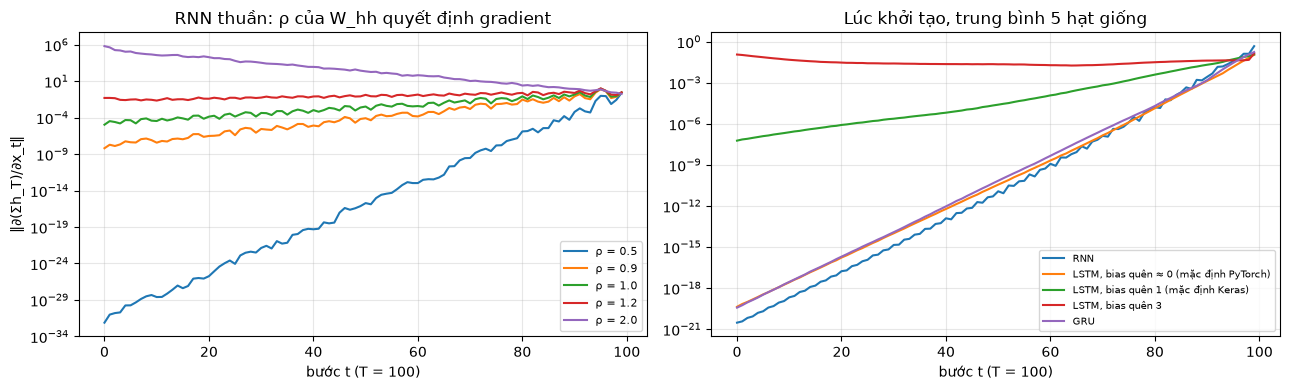

In [7]:
def lstm_with_forget_bias(fb, H=32):
    layer = nn.LSTM(1, H, batch_first=True)
    with torch.no_grad():                   # thu tu cong trong PyTorch: i, f, g, o
        layer.bias_ih_l0[H:2 * H].fill_(fb)
        layer.bias_hh_l0[H:2 * H].fill_(0.0)
    return layer


cells = {"RNN": lambda: nn.RNN(1, 32, batch_first=True),
         "LSTM, bias quên ≈ 0 (mặc định PyTorch)": lambda: nn.LSTM(1, 32, batch_first=True),
         "LSTM, bias quên 1 (mặc định Keras)": lambda: lstm_with_forget_bias(1.0),
         "LSTM, bias quên 3": lambda: lstm_with_forget_bias(3.0),
         "GRU": lambda: nn.GRU(1, 32, batch_first=True)}
cell_decay = {}
for name, make in cells.items():
    runs = []
    for seed in range(5):
        torch.manual_seed(seed)
        runs.append(grad_wrt_inputs(make(), seed=seed))
    cell_decay[name] = np.mean(runs, axis=0)
    print("%-38s |grad| t=0: %.1e   t=50: %.1e   t=99: %.1e"
          % (name, cell_decay[name][0], cell_decay[name][50], cell_decay[name][99]))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
for rho in rhos:
    a1.semilogy(np.arange(100), decay[rho], label="ρ = %.1f" % rho)
a1.set_xlabel("bước t (T = 100)")
a1.set_ylabel("‖∂(Σh_T)/∂x_t‖")
a1.set_title("RNN thuần: ρ của W_hh quyết định gradient")
a1.legend(fontsize=8)
for name, v in cell_decay.items():
    a2.semilogy(np.arange(100), v, label=name)
a2.set_xlabel("bước t (T = 100)")
a2.set_title("Lúc khởi tạo, trung bình 5 hạt giống")
a2.legend(fontsize=7.5)
fig.tight_layout()
save(fig, "fig_vanishing.png")
plt.show()

Chống bùng nổ thì đơn giản: cắt chuẩn gradient. `clip_grad_norm_` tính chuẩn của toàn
bộ gradient, nếu lớn hơn ngưỡng thì chia tỉ lệ cho bằng ngưỡng, giữ nguyên hướng. Cả
notebook 03 và 04 đều cắt ở 1,0 (Keras dùng `global_clipnorm=1.0` để có đúng cùng
phép tính, còn `clipnorm` của Keras cắt riêng từng biến).

In [8]:
torch.manual_seed(0)
layer = nn.RNN(1, 32, batch_first=True)
with torch.no_grad():
    layer.weight_hh_l0.copy_(2.0 * torch.linalg.qr(torch.randn(32, 32))[0])
out, _ = layer(torch.randn(16, 100, 1))
out[:, -1].pow(2).sum().backward()
before = nn.utils.clip_grad_norm_(layer.parameters(), max_norm=1.0)
after = torch.sqrt(sum(p.grad.norm() ** 2 for p in layer.parameters()))
print("chuan gradient truoc khi cat: %.3e | sau khi cat: %.3f" % (before, after))

chuan gradient truoc khi cat: 1.176e+08 | sau khi cat: 1.000


Gradient tiêu biến thì không cắt được. Có ba cách xử lý: khởi tạo W_hh gần trực giao
với ρ ≈ 1, dùng chuỗi ngắn hơn, hoặc đổi sang ô có cổng như LSTM, GRU. Cách thứ ba là
nội dung của hai mục tiếp theo.

## 6. LSTM

LSTM thêm một ô nhớ c_t và ba cổng. Theo đúng thứ tự PyTorch lưu trong trọng số
(i, f, g, o):

$$i_t = \sigma(W_{ii} x_t + b_{ii} + W_{hi} h_{t-1} + b_{hi}) \quad \text{cổng vào: ghi bao nhiêu}$$
$$f_t = \sigma(W_{if} x_t + b_{if} + W_{hf} h_{t-1} + b_{hf}) \quad \text{cổng quên: giữ bao nhiêu}$$
$$g_t = \tanh(W_{ig} x_t + b_{ig} + W_{hg} h_{t-1} + b_{hg}) \quad \text{nội dung ứng viên}$$
$$o_t = \sigma(W_{io} x_t + b_{io} + W_{ho} h_{t-1} + b_{ho}) \quad \text{cổng ra: lộ bao nhiêu}$$
$$c_t = f_t \odot c_{t-1} + i_t \odot g_t, \qquad h_t = o_t \odot \tanh(c_t)$$

Bốn phép biến đổi tuyến tính được gộp thành một ma trận W_ih kích thước 4H x F và một
W_hh kích thước 4H x H, rồi tách ra bằng `np.split(..., 4)`.

In [9]:
def lstm_forward_numpy(X, W_ih, W_hh, b_ih, b_hh):
    """LSTM mot tang. X: (B, T, F). Tra ve (B, T, H), (h_T, c_T) va gia tri cac cong."""
    B, T, _ = X.shape
    H = W_hh.shape[1]
    h, c = np.zeros((B, H)), np.zeros((B, H))
    hs, gates = [], []
    for t in range(T):
        z = X[:, t] @ W_ih.T + b_ih + h @ W_hh.T + b_hh      # (B, 4H)
        i, f, g, o = np.split(z, 4, axis=1)                  # thu tu cong cua PyTorch
        i, f, g, o = sigm(i), sigm(f), np.tanh(g), sigm(o)
        c = f * c + i * g                                    # ghi / quen tren o nho
        h = o * np.tanh(c)                                   # doc o nho ra trang thai an
        hs.append(h)
        gates.append((i.mean(), f.mean(), o.mean()))
    return np.stack(hs, axis=1), (h, c), np.array(gates)


torch.manual_seed(0)
lstm = nn.LSTM(3, 4, batch_first=True)
out_t, (hn_t, cn_t) = lstm(X)
W = {k: v.detach().numpy().astype(np.float64) for k, v in lstm.named_parameters()}
out_np, (hn_np, cn_np), gates = lstm_forward_numpy(
    X.numpy().astype(np.float64), W["weight_ih_l0"], W["weight_hh_l0"], W["bias_ih_l0"],
    W["bias_hh_l0"])
for k, v in W.items():
    print("%-14s %s" % (k, v.shape))
print("chenh lech lon nhat: out %.2e, h_n %.2e, c_n %.2e"
      % (np.abs(out_np - out_t.detach().numpy()).max(),
         np.abs(hn_np - hn_t[0].detach().numpy()).max(),
         np.abs(cn_np - cn_t[0].detach().numpy()).max()))
print("trung binh cong i, f, o o 5 buoc:\n", gates.round(3))

weight_ih_l0   (16, 3)
weight_hh_l0   (16, 4)
bias_ih_l0     (16,)
bias_hh_l0     (16,)
chenh lech lon nhat: out 3.08e-08, h_n 2.23e-08, c_n 6.31e-08
trung binh cong i, f, o o 5 buoc:
 [[0.414 0.559 0.471]
 [0.464 0.516 0.513]
 [0.448 0.479 0.495]
 [0.479 0.455 0.513]
 [0.455 0.48  0.497]]


## 7. GRU

GRU gộp ô nhớ vào trạng thái ẩn và chỉ dùng hai cổng. Thứ tự trong trọng số PyTorch
là (r, z, n):

$$r_t = \sigma(W_{ir} x_t + b_{ir} + W_{hr} h_{t-1} + b_{hr}) \quad \text{cổng đặt lại}$$
$$z_t = \sigma(W_{iz} x_t + b_{iz} + W_{hz} h_{t-1} + b_{hz}) \quad \text{cổng cập nhật}$$
$$n_t = \tanh(W_{in} x_t + b_{in} + r_t \odot (W_{hn} h_{t-1} + b_{hn}))$$
$$h_t = (1 - z_t) \odot n_t + z_t \odot h_{t-1}$$

Chú ý r_t nhân vào **sau** phép biến đổi tuyến tính của h_{t-1} (có cả bias b_hn).
Đây là biến thể mà cuDNN dùng, và cũng là mặc định `reset_after=True` của Keras. Khi
z_t ≈ 1 thì h_t ≈ h_{t-1}: trạng thái được sao chép nguyên vẹn, gradient đi qua với hệ
số z_t, cùng cơ chế như cổng quên của LSTM.

In [10]:
def gru_forward_numpy(X, W_ih, W_hh, b_ih, b_hh):
    B, T, _ = X.shape
    H = W_hh.shape[1]
    h = np.zeros((B, H))
    hs = []
    for t in range(T):
        i_r, i_z, i_n = np.split(X[:, t] @ W_ih.T + b_ih, 3, axis=1)
        h_r, h_z, h_n = np.split(h @ W_hh.T + b_hh, 3, axis=1)
        r = sigm(i_r + h_r)
        z = sigm(i_z + h_z)
        n = np.tanh(i_n + r * h_n)          # r nhan sau phep bien doi tuyen tinh cua h
        h = (1 - z) * n + z * h
        hs.append(h)
    return np.stack(hs, axis=1), h


torch.manual_seed(0)
gru = nn.GRU(3, 4, batch_first=True)
out_t, hn_t = gru(X)
W = {k: v.detach().numpy().astype(np.float64) for k, v in gru.named_parameters()}
out_np, hn_np = gru_forward_numpy(X.numpy().astype(np.float64), W["weight_ih_l0"],
                                  W["weight_hh_l0"], W["bias_ih_l0"], W["bias_hh_l0"])
print("chenh lech lon nhat: out %.2e, h_n %.2e"
      % (np.abs(out_np - out_t.detach().numpy()).max(),
         np.abs(hn_np - hn_t[0].detach().numpy()).max()))

F_, H_ = 3, 32
print("\nSo tham so voi F = %d, H = %d:" % (F_, H_))
for name, layer, k in [("RNN", nn.RNN(F_, H_), 1), ("GRU", nn.GRU(F_, H_), 3),
                       ("LSTM", nn.LSTM(F_, H_), 4)]:
    n = sum(p.numel() for p in layer.parameters())
    print("  %-4s %6d = %d * H(F + H + 2) = %d" % (name, n, k, k * H_ * (F_ + H_ + 2)))

chenh lech lon nhat: out 4.82e-08, h_n 3.93e-08

So tham so voi F = 3, H = 32:
  RNN    1184 = 1 * H(F + H + 2) = 1184
  GRU    3552 = 3 * H(F + H + 2) = 3552
  LSTM   4736 = 4 * H(F + H + 2) = 4736


## 8. Thí nghiệm trí nhớ: nhớ một dấu hiệu qua T bước nhiễu

Mục 5 đo gradient lúc khởi tạo. Mục này đo hệ quả khi huấn luyện thật. Bài toán được
thiết kế để chỉ có một cách giải là nhớ lâu:

- Mỗi chuỗi dài T bước, mỗi bước 2 giá trị. Bước 0 chứa dấu hiệu s = +1 hoặc -1 kèm cờ
  đánh dấu 1. T - 1 bước sau là nhiễu chuẩn N(0, 1) với cờ 0.
- Nhãn là s > 0. Mạng chỉ được đọc đầu ra ở bước cuối, nên phải mang s qua T - 1 bước
  nhiễu có cùng độ lớn với chính tín hiệu.

Một RNN thuần không có cách nào "đóng cửa" với nhiễu: mỗi bước nhiễu đều đi qua cùng
W_ih và trộn vào trạng thái. LSTM và GRU có cổng nhân theo từng phần tử nên về nguyên
tắc học được "chỉ ghi khi cờ bằng 1, sau đó giữ nguyên". Năm cấu hình, ba độ dài T, hai
hạt giống, tối đa 1.500 bước Adam với batch 128 (dữ liệu sinh mới ở mỗi bước). Một lần
chạy được coi là giải xong khi trung bình trượt của loss xuống dưới 0,05.

In [11]:
def memory_batch(n, T, gen, noise=1.0):
    """Buoc 0: dau hieu s = +-1 va co 1. Cac buoc sau: nhieu N(0, 1) va co 0. Nhan: s > 0."""
    s = torch.randint(0, 2, (n,), generator=gen).float() * 2 - 1
    x = torch.randn(n, T, 2, generator=gen) * noise
    x[:, :, 1] = 0.0
    x[:, 0, 0] = s
    x[:, 0, 1] = 1.0
    return x, (s > 0).float()


class MemNet(nn.Module):
    def __init__(self, cell, forget_bias=None, H=32):
        super().__init__()
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell](2, H, batch_first=True)
        if forget_bias is not None:              # chi dung cho LSTM, cong f la khoi thu hai
            with torch.no_grad():
                self.rnn.bias_ih_l0[H:2 * H].fill_(forget_bias)
                self.rnn.bias_hh_l0[H:2 * H].fill_(0.0)
        self.head = nn.Linear(H, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)


def memory_run(cell, fb, T, seed, max_steps=1500, lr=5e-3):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(100 + seed)
    model = MemNet(cell, fb)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ema, solved = None, None
    for step in range(1, max_steps + 1):
        x, y = memory_batch(128, T, gen)
        loss = nn.functional.binary_cross_entropy_with_logits(model(x), y)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        ema = loss.item() if ema is None else 0.9 * ema + 0.1 * loss.item()
        if ema < 0.05:
            solved = step
            break
    xt, yt = memory_batch(2000, T, torch.Generator().manual_seed(999))
    with torch.no_grad():
        acc = ((model(xt) > 0).float() == yt).float().mean().item()
    return acc, solved


configs = [("RNN", None, "RNN"), ("LSTM", None, "LSTM, b_f ≈ 0 (PyTorch)"),
           ("LSTM", 1.0, "LSTM, b_f = 1 (Keras)"), ("LSTM", 3.0, "LSTM, b_f = 3"),
           ("GRU", None, "GRU")]
mem_rows = []
t_start = time.perf_counter()
for T in (25, 50, 100):
    for cell, fb, label in configs:
        for seed in (0, 1):
            t0 = time.perf_counter()
            acc, solved = memory_run(cell, fb, T, seed)
            mem_rows.append(dict(T=T, cau_hinh=label, seed=seed, acc=acc, giai_o_buoc=solved))
            print("T=%3d  %-24s seed %d  acc %.3f  giai o buoc %5s  %5.1f s"
                  % (T, label, seed, acc, solved, time.perf_counter() - t0))
print("tong thoi gian: %.0f s" % (time.perf_counter() - t_start))

T= 25  RNN                      seed 0  acc 1.000  giai o buoc   106    8.4 s


T= 25  RNN                      seed 1  acc 0.495  giai o buoc  None   13.8 s


T= 25  LSTM, b_f ≈ 0 (PyTorch)  seed 0  acc 0.495  giai o buoc  None   13.4 s


T= 25  LSTM, b_f ≈ 0 (PyTorch)  seed 1  acc 0.505  giai o buoc  None   11.8 s


T= 25  LSTM, b_f = 1 (Keras)    seed 0  acc 0.997  giai o buoc    74    0.7 s


...

T=100  LSTM, b_f = 1 (Keras)    seed 1  acc 0.505  giai o buoc  None   35.0 s


T=100  LSTM, b_f = 3            seed 0  acc 0.992  giai o buoc   814   20.4 s


T=100  LSTM, b_f = 3            seed 1  acc 0.495  giai o buoc  None   38.1 s


T=100  GRU                      seed 0  acc 0.515  giai o buoc  None  117.3 s


T=100  GRU                      seed 1  acc 0.495  giai o buoc  None  125.0 s
tong thoi gian: 911 s


T                          25     50     100
cau_hinh                                    
RNN                      0.748  0.429  0.519
LSTM, b_f ≈ 0 (PyTorch)  0.500  0.500  0.506
LSTM, b_f = 1 (Keras)    0.998  0.500  0.509
LSTM, b_f = 3            0.998  0.995  0.743
GRU                      1.000  0.501  0.505


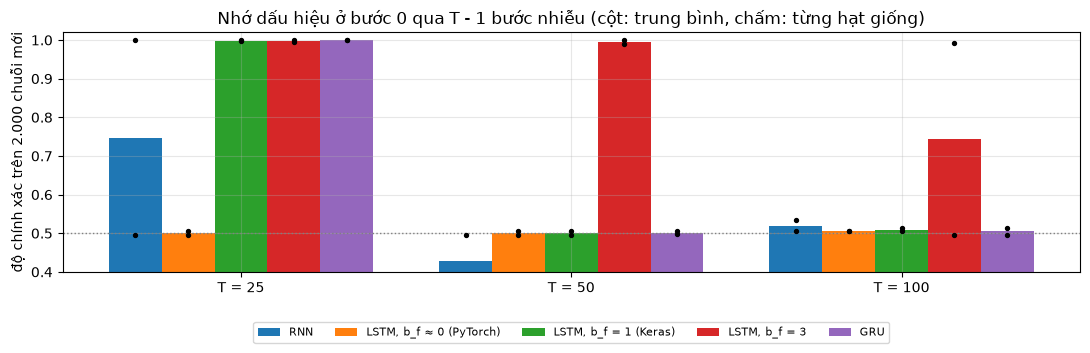

In [12]:
import pandas as pd

mem = pd.DataFrame(mem_rows)
D.save_result("concept__memory", dict(rows=mem_rows, rho_decay={str(k): v for k, v in decay.items()}))
print(mem.pivot_table(index="cau_hinh", columns="T", values="acc", aggfunc="mean",
                      sort=False).round(3))

fig, ax = plt.subplots(figsize=(11, 3.8))
labels = [c[2] for c in configs]
w = 0.16
for j, (_, _, label) in enumerate(configs):
    for i, T in enumerate((25, 50, 100)):
        accs = mem.query("T == @T and cau_hinh == @label")["acc"].to_numpy()
        xpos = i + (j - 2) * w
        ax.bar(xpos, accs.mean(), width=w, color=plt.cm.tab10(j),
               label=label if i == 0 else None)
        ax.scatter([xpos] * len(accs), accs, c="k", s=8, zorder=3)
ax.axhline(0.5, c="gray", ls=":", lw=1)
ax.set_xticks(range(3), ["T = 25", "T = 50", "T = 100"])
ax.set_ylim(0.4, 1.02)
ax.set_ylabel("độ chính xác trên 2.000 chuỗi mới")
ax.set_title("Nhớ dấu hiệu ở bước 0 qua T - 1 bước nhiễu (cột: trung bình, chấm: từng hạt giống)")
ax.legend(fontsize=8, ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.32))
fig.tight_layout()
save(fig, "fig_memory.png")
plt.show()

MEMORY_RESULT

## 9. Các kiểu kiến trúc và API cần biết

| Kiểu | Vào | Ra | Ví dụ | Trong PyTorch |
|---|---|---|---|---|
| nhiều-một | chuỗi | một giá trị | Churn, dự báo lợi suất ngày mai | `out[:, -1]` hoặc `h_n[-1]` |
| nhiều-nhiều (cùng độ dài) | chuỗi | chuỗi | gán nhãn từng bước | toàn bộ `out` |
| một-nhiều, seq2seq | vectơ / chuỗi | chuỗi | sinh văn bản, dịch máy | encoder + decoder |

Hai biến thể hay gặp: xếp chồng nhiều tầng (`num_layers`), trong đó đầu ra `out` của
tầng dưới là đầu vào của tầng trên; và hai chiều (`bidirectional=True`), trong đó một
RNN đọc xuôi, một RNN đọc ngược rồi ghép hai trạng thái lại. Mô hình hai chiều không
dùng được cho dự báo chuỗi thời gian vì chiều ngược cần nhìn thấy tương lai.

In [13]:
torch.manual_seed(0)
deep = nn.LSTM(input_size=3, hidden_size=8, num_layers=2, bidirectional=True, batch_first=True)
out, (hn, cn) = deep(torch.randn(4, 10, 3))
print("out", tuple(out.shape), "= (batch, time, 2 chieu x hidden)")
print("h_n", tuple(hn.shape), "= (so tang x 2 chieu, batch, hidden)")
print("h_n tang tren, chieu xuoi trung out[:, -1, :8]:", torch.allclose(hn[-2], out[:, -1, :8]))
print("h_n tang tren, chieu nguoc trung out[:, 0, 8:]:", torch.allclose(hn[-1], out[:, 0, 8:]))

out (4, 10, 16) = (batch, time, 2 chieu x hidden)
h_n (4, 4, 8) = (so tang x 2 chieu, batch, hidden)
h_n tang tren, chieu xuoi trung out[:, -1, :8]: True
h_n tang tren, chieu nguoc trung out[:, 0, 8:]: True


Chiều ngược đọc từ bước cuối về bước đầu, nên trạng thái cuối cùng của nó nằm ở
`out[:, 0]` chứ không phải `out[:, -1]`. Nhầm chỗ này là lỗi rất phổ biến.

Khi các chuỗi trong một batch dài ngắn khác nhau, phải đệm cho bằng nhau rồi báo cho
RNN độ dài thật bằng `pack_padded_sequence`, nếu không trạng thái cuối sẽ là trạng thái
sau khi đọc cả phần đệm:

In [14]:
torch.manual_seed(0)
r = nn.GRU(1, 4, batch_first=True)
lengths = torch.tensor([5, 3, 2])
padded = torch.zeros(3, 5, 1)
for i, L in enumerate(lengths):
    padded[i, :L, 0] = torch.randn(int(L))
packed = nn.utils.rnn.pack_padded_sequence(padded, lengths, batch_first=True,
                                           enforce_sorted=False)
_, h_packed = r(packed)
_, h_naive = r(padded)
_, h_true = r(padded[1:2, :3])                      # chuoi thu hai, chi 3 buoc that
print("chuoi 2 - dung pack trung ket qua dung:", torch.allclose(h_packed[0, 1], h_true[0, 0]))
print("chuoi 2 - khong pack trung ket qua dung:", torch.allclose(h_naive[0, 1], h_true[0, 0]))

chuoi 2 - dung pack trung ket qua dung: True
chuoi 2 - khong pack trung ket qua dung: False


Bài này không cần tới vì mọi chuỗi đều cùng độ dài (11 bước với Churn, 60 bước với
AMZN), nhưng đây là tình huống bình thường với văn bản hay lịch sử giao dịch thật.

## 10. Bảng đối chiếu các hàm dùng trong bài

| Khái niệm | PyTorch | Keras |
|---|---|---|
| ô RNN thuần | `nn.RNN(F, H, batch_first=True)` | `layers.SimpleRNN(H)` |
| LSTM | `nn.LSTM(F, H, batch_first=True)` | `layers.LSTM(H)` |
| GRU | `nn.GRU(F, H, batch_first=True)` | `layers.GRU(H)` (mặc định `reset_after=True`) |
| lấy toàn bộ chuỗi đầu ra | luôn trả về `out` | `return_sequences=True` |
| lấy trạng thái cuối | `h_n` (và `c_n` với LSTM) | `return_state=True` |
| nhiều tầng | `num_layers=2` | xếp hai lớp, lớp dưới `return_sequences=True` |
| hai chiều | `bidirectional=True` | `layers.Bidirectional(layers.LSTM(H))` |
| độ dài khác nhau | `pack_padded_sequence` | `layers.Masking` hoặc `mask_zero=True` |
| cắt gradient | `clip_grad_norm_(params, 1.0)` | `Adam(global_clipnorm=1.0)` |
| hàm mất mát phân lớp | `BCEWithLogitsLoss` | `BinaryCrossentropy(from_logits=True)` |
| dừng sớm | tự viết (notebook 03) | `callbacks.EarlyStopping(restore_best_weights=True)` |
| bias cổng quên LSTM ban đầu | 0 | 1 (`unit_forget_bias=True`) |